# LuminaTech Customer Churn Analysis

**Business question:** Which LuminaTech customers stop buying, how much revenue do they take with them, and can we flag at-risk customers early enough for the sales team to act?

**Churn definition:** a customer who bought at least once in calendar year **2023** and made **no purchase in 2024**.

All customer behaviour is measured using 2023 data only, so the model uses only information that was available at the end of 2023 (no look-ahead).

This notebook extends `01_sales_performance_analysis.ipynb` with a customer-level view.

**Contents**
1. Load and clean the data
2. Build customer-level features
3. How big is the churn problem?
4. Who churns?
5. Predicting churn
6. What drives churn?
7. Scoring customers for the next year
8. Recommendations and limitations

## 1. Load and clean the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

pd.set_option('display.width', 160)
pd.set_option('display.float_format', '{:,.3f}'.format)

# Chart style
BLUE, ORANGE, INK, MUTED, GRID = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': GRID,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'font.size': 10, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})

Cleaning follows the same rules as the main LuminaTech sales analysis:
- strip whitespace and treat `NULL` / `NA` as missing,
- recode `AUS` to `AUD` and convert sales and cost to AUD with the same exchange rates,
- drop rows without a customer code. These are almost all from company 950 (the NZD business), which does not record customer codes, so churn cannot be measured for it.

In [2]:
RATES = {'AUD': 1.0, 'USD': 0.65, 'NZD': 1.13, 'EUR': 0.49}   # 1 AUD = x units of currency
COLS = ['accounting_date', 'company_code', 'customer_code', 'customer_district_code', 'item_type',
        'business_chain_l1_name', 'salesperson_code', 'order_type_code', 'value_sales', 'value_cost',
        'value_quantity', 'value_price_adjustment', 'currency', 'invoice_number']

def load(path):
    d = pd.read_csv(path, usecols=COLS, dtype=str, encoding='ISO-8859-1',
                    na_values=['NULL', 'NA', 'na', 'Na', ''])
    d = d.dropna(how='all')
    for c in d.columns:
        d[c] = d[c].str.strip()
    d['date'] = pd.to_datetime(d['accounting_date'].str[:8], format='%Y%m%d', errors='coerce')
    d['currency'] = d['currency'].replace({'AUS': 'AUD'})
    rate = d['currency'].map(RATES)
    for c in ['value_sales', 'value_cost']:
        d[c + '_aud'] = pd.to_numeric(d[c], errors='coerce') / rate
    d['price_adj'] = pd.to_numeric(d['value_price_adjustment'], errors='coerce')
    raw_rows = len(d)
    d = d[d['customer_code'].notna() & (d['customer_code'] != '0') & d['date'].notna()]
    print(f'{path}: {raw_rows:,} rows -> {len(d):,} rows with a customer code, '
          f'{d["customer_code"].nunique():,} customers, {d["date"].min():%d %b %Y} to {d["date"].max():%d %b %Y}')
    return d

t23 = load('data/2023.csv')
t24 = load('data/2024.csv')

data/2023.csv: 1,037,197 rows -> 982,542 rows with a customer code, 3,224 customers, 02 Jan 2023 to 31 Dec 2023


data/2024.csv: 951,176 rows -> 885,128 rows with a customer code, 3,225 customers, 02 Jan 2024 to 31 Dec 2024


## 2. Build customer-level features

Each row becomes one customer. Features describe how the customer behaved in 2023, grouped as:
- **Recency, frequency, monetary (RFM):** days since last purchase, number of invoices, months with a purchase, revenue, profit and margin.
- **Breadth:** number of product types bought and number of salespeople involved.
- **Relationship signals:** share of lines that were credits or returns (order types CRD, CRR, CDG, ZCG or negative sales), share with a price adjustment, share ordered through EDI.
- **Trend:** share of 2023 revenue that came in the second half of the year (a falling share hints at a customer fading out).
- **Profile:** main business chain, district and product type.

The label `churned` is 1 if the customer has no transaction in 2024.

In [3]:
CUTOFF = pd.Timestamp('2023-12-31')
CREDIT_TYPES = {'CRD', 'CRR', 'CDG', 'ZCG'}

def mode_or_unknown(s):
    return s.mode().iat[0] if s.notna().any() else 'Unknown'

def build_features(t, cutoff, year_start):
    t = t.copy()
    t['profit'] = t['value_sales_aud'] - t['value_cost_aud']
    t['is_credit'] = t['order_type_code'].isin(CREDIT_TYPES) | (t['value_sales_aud'] < 0)
    t['is_edi'] = t['order_type_code'].eq('EDI')
    h2 = t['date'].dt.month > 6
    g = t.groupby('customer_code')
    f = pd.DataFrame({
        'revenue': g['value_sales_aud'].sum(),
        'profit': g['profit'].sum(),
        'n_invoices': g['invoice_number'].nunique(),
        'active_months': g['date'].apply(lambda s: s.dt.month.nunique()),
        'recency_days': (cutoff - g['date'].max()).dt.days,
        'first_purchase_day': (g['date'].min() - year_start).dt.days,
        'n_item_types': g['item_type'].nunique(),
        'n_salespeople': g['salesperson_code'].nunique(),
        'credit_share': g['is_credit'].mean(),
        'price_adj_share': g['price_adj'].mean(),
        'edi_share': g['is_edi'].mean(),
        'business_chain': g['business_chain_l1_name'].agg(mode_or_unknown),
        'district': g['customer_district_code'].agg(mode_or_unknown),
        'main_item_type': g['item_type'].agg(mode_or_unknown),
    })
    rev_h1 = t[~h2].groupby('customer_code')['value_sales_aud'].sum().clip(lower=0)
    rev_h2 = t[h2].groupby('customer_code')['value_sales_aud'].sum().clip(lower=0)
    total = rev_h1.reindex(f.index, fill_value=0) + rev_h2.reindex(f.index, fill_value=0)
    f['h2_share'] = (rev_h2.reindex(f.index, fill_value=0) / total.replace(0, np.nan))
    f['margin'] = np.where(f['revenue'] > 0, f['profit'] / f['revenue'], np.nan)
    f['avg_invoice_value'] = f['revenue'] / f['n_invoices']
    return f

cust = build_features(t23, CUTOFF, pd.Timestamp('2023-01-01'))
cust['churned'] = (~cust.index.isin(set(t24['customer_code']))).astype(int)
print(cust.shape)
cust.head()

(3224, 18)


,revenue,profit,n_invoices,active_months,recency_days,first_purchase_day,n_item_types,n_salespeople,credit_share,price_adj_share,edi_share,business_chain,district,main_item_type,h2_share,margin,avg_invoice_value,churned
customer_code,,,,,,,,,,,,,,,,,,
1000000200,"1,401.800",792.955,12,8,48,16,4,2,0.034,0.000,0.000,Independent Retailers Association,500,7,0.632,0.566,116.817,0
1000000400,550.000,204.710,1,1,231,133,1,1,0.000,0.000,0.000,EndUser Solutions,500,6,0.000,0.372,550.000,1
1000000600,771.500,354.190,2,2,84,63,2,2,0.000,0.000,0.000,EndUser Solutions,500,7,0.171,0.459,385.750,0
1000031220,237.280,132.994,1,1,75,289,1,1,0.000,0.000,0.000,General Suppliers Pty,710,6,1.000,0.560,237.280,1
1000031420,"1,727.220",785.917,4,3,70,18,3,2,0.000,0.000,0.000,General Suppliers Pty,710,6,0.158,0.455,431.805,0


## 3. How big is the churn problem?

In [4]:
n, n_churn = len(cust), cust['churned'].sum()
rev_total = cust['revenue'].sum()
rev_lost = cust.loc[cust['churned'] == 1, 'revenue'].sum()
new_2024 = len(set(t24['customer_code']) - set(cust.index))

summary = pd.Series({
    'Customers active in 2023': f'{n:,}',
    'Churned (no purchase in 2024)': f'{n_churn:,}',
    'Churn rate': f'{n_churn / n:.1%}',
    'New customers in 2024': f'{new_2024:,}',
    '2023 revenue from churned customers (AUD)': f'{rev_lost:,.0f}',
    'Share of 2023 revenue': f'{rev_lost / rev_total:.1%}',
})
summary.to_frame('Value')

,Value
Customers active in 2023,"3,224"
Churned (no purchase in 2024),431
Churn rate,13.4%
New customers in 2024,432
2023 revenue from churned customers (AUD),"6,198,122"
Share of 2023 revenue,1.6%


In [5]:
cmp = cust.groupby('churned')[['revenue', 'n_invoices', 'active_months', 'recency_days',
                               'n_item_types', 'credit_share', 'margin']].median()
cmp.index = ['Retained (median)', 'Churned (median)']
cmp.T

,Retained (median),Churned (median)
revenue,"28,322.440","1,006.300"
n_invoices,49.000,2.000
active_months,12.000,2.000
recency_days,13.000,159.000
n_item_types,4.000,2.000
credit_share,0.030,0.000
margin,0.487,0.493


**Findings**
- About **1 in 7 customers (13.4%) churned**, but they accounted for only **1.6% of 2023 revenue**. Churn is concentrated among small, occasional buyers rather than key accounts.
- The typical churned customer bought on **2 invoices in 2 months** and had not bought for **159 days** by the end of 2023. The typical retained customer bought every month and last bought 13 days before year end.
- Margins are almost identical between the two groups (~49%), so churn is not driven by customers being sold low-margin products.
- New customers in 2024 replaced the churned ones one for one, so the customer count stayed flat. That hides the churn if management only looks at the headline count.

## 4. Who churns?

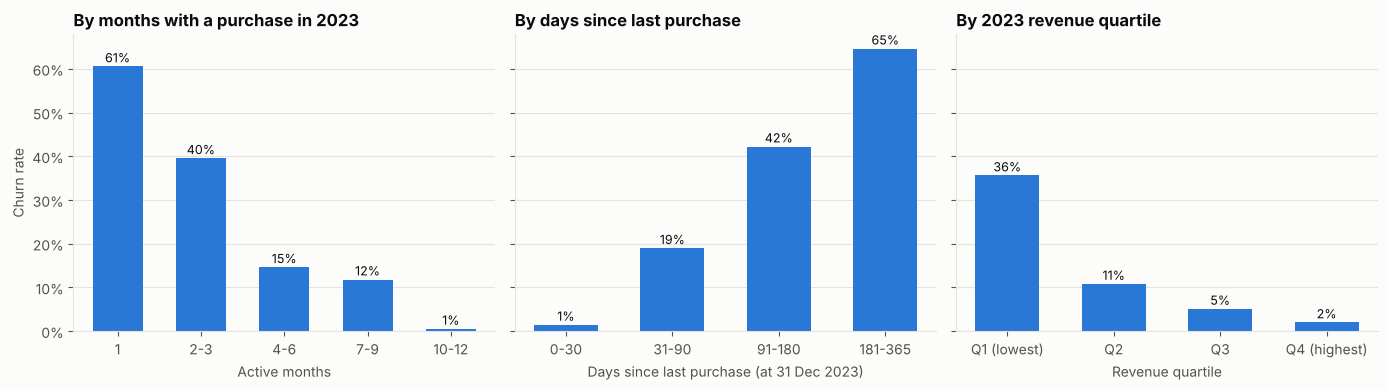

churn_rate  customers
Active months    1                  0.606        322
                 2-3                0.395        354
                 4-6                0.146        342
                 7-9                0.118        305
                 10-12              0.005       1901
Recency (days)   0-30               0.014       2154
                 31-90              0.190        506
                 91-180             0.422        270
                 181-365            0.646        294
Revenue quartile Q1 (lowest)        0.356        806
                 Q2                 0.108        806
                 Q3                 0.051        806
                 Q4 (highest)       0.020        806

In [6]:
def churn_by(series, order=None):
    out = cust.groupby(series, observed=True)['churned'].agg(churn_rate='mean', customers='size')
    return out.reindex(order) if order is not None else out

seg_months = churn_by(pd.cut(cust['active_months'], [0, 1, 3, 6, 9, 12],
                             labels=['1', '2-3', '4-6', '7-9', '10-12']))
seg_recency = churn_by(pd.cut(cust['recency_days'], [-1, 30, 90, 180, 365],
                              labels=['0-30', '31-90', '91-180', '181-365']))
seg_revenue = churn_by(pd.qcut(cust['revenue'].rank(method='first'), 4,
                               labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)']))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (seg, title, xlabel) in zip(axes, [
        (seg_months, 'By months with a purchase in 2023', 'Active months'),
        (seg_recency, 'By days since last purchase', 'Days since last purchase (at 31 Dec 2023)'),
        (seg_revenue, 'By 2023 revenue quartile', 'Revenue quartile')]):
    bars = ax.bar(seg.index.astype(str), seg['churn_rate'], color=BLUE, width=0.6)
    for b, v, c in zip(bars, seg['churn_rate'], seg['customers']):
        ax.annotate(f'{v:.0%}', (b.get_x() + b.get_width() / 2, v), xytext=(0, 3),
                    textcoords='offset points', ha='center', fontsize=9, color=INK)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('Churn rate')
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
plt.tight_layout()
plt.show()
pd.concat({'Active months': seg_months, 'Recency (days)': seg_recency, 'Revenue quartile': seg_revenue})

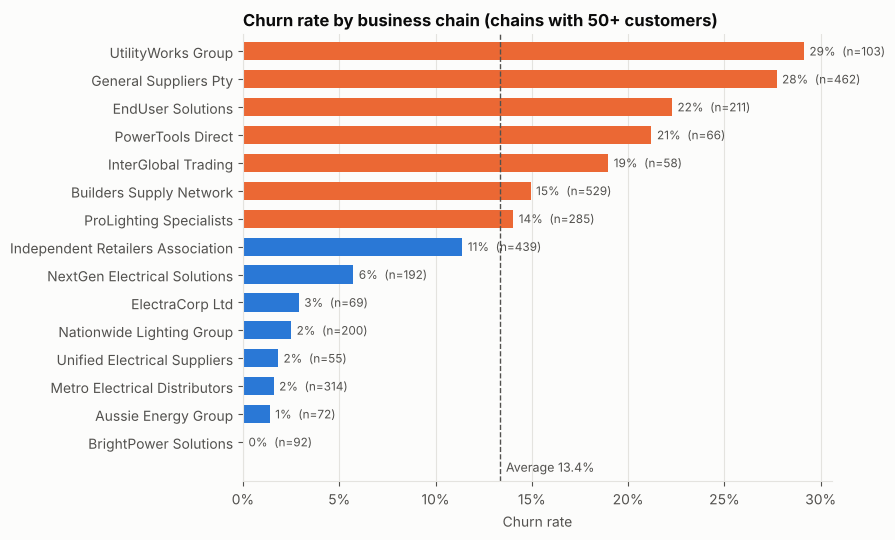

In [7]:
chains = churn_by(cust['business_chain']).query('customers >= 50').sort_values('churn_rate')
avg = cust['churned'].mean()
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = [ORANGE if r > avg else BLUE for r in chains['churn_rate']]
ax.barh(chains.index, chains['churn_rate'], color=colors, height=0.65)
ax.axvline(avg, color=MUTED, lw=1, ls='--')
ax.annotate(f'Average {avg:.1%}', (avg, -0.9), xytext=(4, 0), textcoords='offset points',
            color=MUTED, fontsize=9, va='center')
ax.set_ylim(-1.4, len(chains) - 0.4)
for i, (v, c) in enumerate(zip(chains['churn_rate'], chains['customers'])):
    ax.annotate(f'{v:.0%}  (n={c})', (v, i), xytext=(4, 0), textcoords='offset points',
                va='center', fontsize=8.5, color=MUTED)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_title('Churn rate by business chain (chains with 50+ customers)')
ax.set_xlabel('Churn rate')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

In [8]:
# Do returns and credits signal churn? Compare customers of similar activity.
active = cust[cust['active_months'] >= 4].copy()
active['credit_band'] = pd.cut(active['credit_share'], [-0.001, 0, 0.05, 0.10, 1],
                               labels=['None', 'Up to 5%', '5-10%', 'Over 10%'])
active.groupby('credit_band', observed=True)['churned'].agg(churn_rate='mean', customers='size')

,churn_rate,customers
credit_band,,
None,0.078,489
Up to 5%,0.011,1034
5-10%,0.027,658
Over 10%,0.079,367


**Findings**
- **Activity is the clearest signal.** Customers who bought in only 1 month of 2023 churned at about **61%**, compared with under **1%** for customers who bought in 10 or more months.
- **Recency matters:** churn rises from about 1% (bought in the last 30 days of 2023) to about **65%** (no purchase for 6+ months).
- **Small accounts churn most:** the lowest revenue quartile churned at about 36%, the top quartile at about 2%.
- **Business chains differ widely**, from almost no churn (BrightPower Solutions, Metro Electrical Distributors) to around **28–29%** (General Suppliers Pty, UtilityWorks Group). Part of this reflects how many small accounts each chain has.
- **Returns and credits:** among customers who bought in at least 4 months, those whose credit or return lines are under 5% churn the least (about 1%). Churn rises to about **8%** when more than 10% of lines are credits or returns. Customers with no credits at all also churn at about 8%, likely because they buy less and have a looser relationship. The regression in section 6 tests the effect while controlling for activity.

## 5. Predicting churn

The goal is to rank customers by churn risk so the sales team can focus on the riskiest ones.

Three approaches are compared with **5-fold stratified cross-validation**, so every customer is scored by a model that did not see them during training:
1. **Baseline:** rank by days since last purchase only (a simple rule a sales manager could use without a model).
2. **Logistic regression** on eight behavioural features (interpretable).
3. **Random forest** on the same features (captures non-linear effects).

Metrics:
- **ROC-AUC:** how well the model ranks churners above non-churners (0.5 = random, 1 = perfect).
- **PR-AUC:** precision and recall for the churn class, more informative when churners are the minority (baseline = churn rate, 0.134).
- **Top 10% precision and capture:** if the team calls the 10% of customers with the highest risk, how many are real churners, and what share of all churners do they reach?

In [9]:
def model_matrix(f):
    X = pd.DataFrame({
        'recency_days': f['recency_days'],
        'active_months': f['active_months'],
        'log_revenue': np.log1p(f['revenue'].clip(lower=0)),
        'n_item_types': f['n_item_types'],
        'credit_share': f['credit_share'],
        'h2_share': f['h2_share'],
        'first_purchase_day': f['first_purchase_day'],
        'margin': f['margin'].clip(-1, 1),
    })
    return X

X = model_matrix(cust)
FILL = X.median()          # medians from the training year, reused when scoring 2024
X = X.fillna(FILL)
y = cust['churned']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'Random forest': RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                                            class_weight='balanced', random_state=42, n_jobs=-1),
}
scores = {'Baseline: recency only': X['recency_days'].values}
for name, m in models.items():
    scores[name] = cross_val_predict(m, X, y, cv=cv, method='predict_proba')[:, 1]

def top_decile(y, s):
    top = np.argsort(-s)[: int(len(s) * 0.10)]
    return y.iloc[top].mean(), y.iloc[top].sum() / y.sum()

rows = []
for name, s in scores.items():
    prec, cap = top_decile(y, s)
    rows.append({'Model': name, 'ROC-AUC': roc_auc_score(y, s), 'PR-AUC': average_precision_score(y, s),
                 'Top 10% precision': prec, 'Top 10% capture': cap})
results = pd.DataFrame(rows).set_index('Model')
results

,ROC-AUC,PR-AUC,Top 10% precision,Top 10% capture
Model,,,,
Baseline: recency only,0.913,0.606,0.634,0.473
Logistic regression,0.930,0.661,0.655,0.490
Random forest,0.935,0.654,0.652,0.487


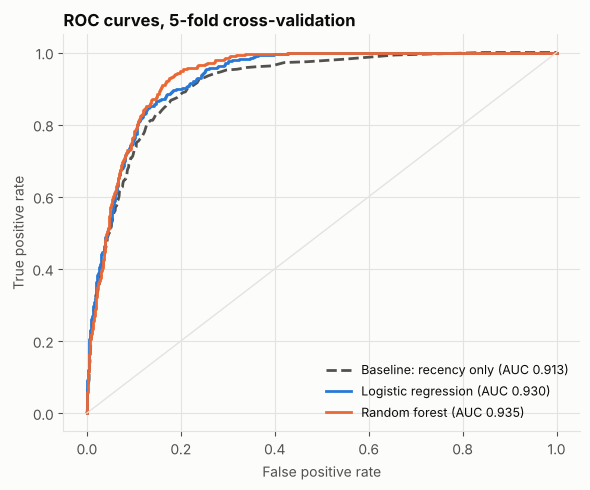

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
styles = {'Baseline: recency only': (MUTED, '--'), 'Logistic regression': (BLUE, '-'), 'Random forest': (ORANGE, '-')}
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y, s)
    c, ls = styles[name]
    ax.plot(fpr, tpr, color=c, ls=ls, lw=2, label=f'{name} (AUC {roc_auc_score(y, s):.3f})')
ax.plot([0, 1], [0, 1], color=GRID, lw=1)
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC curves, 5-fold cross-validation')
ax.legend(frameon=False, loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

**Findings**
- Days since last purchase on its own is already a strong signal (ROC-AUC ≈ 0.91).
- Both models improve on it modestly (ROC-AUC ≈ 0.93, PR-AUC ≈ 0.66 vs 0.61 for the baseline). The random forest has a marginally higher ROC-AUC but a slightly lower PR-AUC, so the simpler, explainable **logistic regression is chosen**.
- If the sales team contacts the **10% of customers with the highest predicted risk**, about **two in three are real churners** (vs 13% at random, roughly a **5x lift**), and they reach about **half of all churners**.

## 6. What drives churn?

A logistic regression on standardised features (statsmodels) shows the direction and size of each effect. An **odds ratio** above 1 means a one-standard-deviation increase in the feature raises the odds of churning; below 1 means it lowers them. All effects are estimated while holding the other features constant.

In [11]:
Z = (X - X.mean()) / X.std()
logit = sm.Logit(y, sm.add_constant(Z)).fit(disp=0)
coef = pd.DataFrame({'odds_ratio': np.exp(logit.params), 'p_value': logit.pvalues,
                     'ci_low': np.exp(logit.conf_int()[0]), 'ci_high': np.exp(logit.conf_int()[1])}).drop('const')
coef = coef.sort_values('odds_ratio')
print(f'Pseudo R-squared: {logit.prsquared:.3f}')
coef

Pseudo R-squared: 0.449


,odds_ratio,p_value,ci_low,ci_high
active_months,0.240,0.000,0.161,0.358
n_item_types,0.668,0.011,0.491,0.911
h2_share,0.947,0.453,0.821,1.092
first_purchase_day,0.947,0.578,0.782,1.147
margin,0.977,0.633,0.886,1.076
log_revenue,1.065,0.517,0.880,1.290
credit_share,1.506,0.000,1.298,1.747
recency_days,1.610,0.000,1.325,1.957


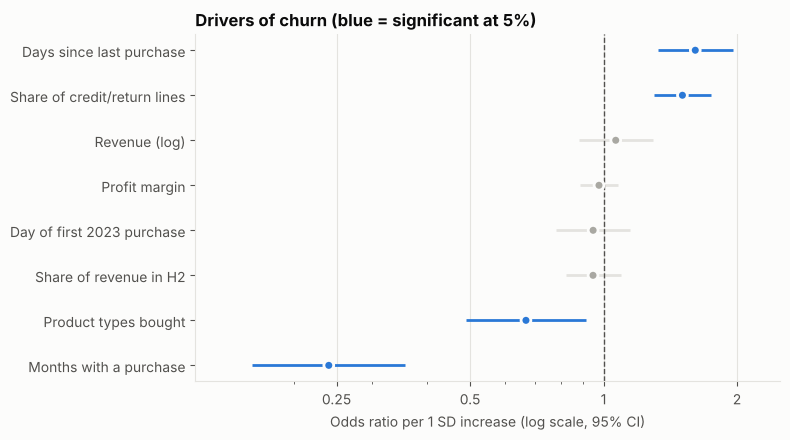

In [12]:
labels = {'recency_days': 'Days since last purchase', 'active_months': 'Months with a purchase',
          'log_revenue': 'Revenue (log)', 'n_item_types': 'Product types bought',
          'credit_share': 'Share of credit/return lines', 'h2_share': 'Share of revenue in H2',
          'first_purchase_day': 'Day of first 2023 purchase', 'margin': 'Profit margin'}
fig, ax = plt.subplots(figsize=(8, 4.5))
sig = coef['p_value'] < 0.05
yy = np.arange(len(coef))
ax.hlines(yy, coef['ci_low'], coef['ci_high'], color=np.where(sig, BLUE, GRID), lw=2)
ax.scatter(coef['odds_ratio'], yy, color=np.where(sig, BLUE, '#a9a8a2'), s=50, zorder=3,
           edgecolor='#fcfcfb', linewidth=2)
ax.axvline(1, color=MUTED, lw=1, ls='--')
ax.set_yticks(yy, [labels[i] for i in coef.index])
ax.set_xscale('log')
ax.set_xlim(0.12, 2.5)
ax.xaxis.set_minor_formatter(plt.matplotlib.ticker.NullFormatter())
ax.set_xticks([0.25, 0.5, 1, 2], ['0.25', '0.5', '1', '2'])
ax.set_xlabel('Odds ratio per 1 SD increase (log scale, 95% CI)')
ax.set_title('Drivers of churn (blue = significant at 5%)')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Findings**
- **Buying regularly is the strongest protection.** Each additional standard deviation in months with a purchase (about 4 months) cuts the odds of churning by roughly **three quarters** (odds ratio ≈ 0.24).
- **Time since last purchase** raises the odds of churning by about **60%** per standard deviation, even after accounting for how often the customer bought.
- **Returns and credits are an early warning sign:** a higher share of credit or return lines raises the odds of churning by about **50%** per standard deviation. A poor product or service experience may push customers away.
- **Broader customers stay:** customers buying more product types are less likely to churn (odds ratio ≈ 0.67).
- Once activity is accounted for, **revenue, margin, start date and the H2 revenue share do not add significant information**. Size matters mainly because big customers also buy more often.

## 7. Scoring customers for the next year

The chosen model is retrained on all 2023 customers and applied to customers' **2024 behaviour** to estimate who is at risk of not buying in 2025. Customers are grouped into risk bands so the sales team gets a short, actionable list.

*Caveat: this assumes the 2023→2024 churn pattern also holds for 2024→2025. The 2025 outcome is not in the data, so these scores cannot be checked yet.*

In [13]:
final = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X, y)

cust24 = build_features(t24, pd.Timestamp('2024-12-31'), pd.Timestamp('2024-01-01'))
X24 = model_matrix(cust24).fillna(FILL)
cust24['churn_risk'] = final.predict_proba(X24)[:, 1]
cust24['risk_band'] = pd.cut(cust24['churn_risk'], [0, 0.2, 0.5, 1], labels=['Low (<20%)', 'Medium (20-50%)', 'High (50%+)'])

bands = cust24.groupby('risk_band', observed=True).agg(
    customers=('churn_risk', 'size'), revenue_2024_aud=('revenue', 'sum'),
    median_active_months=('active_months', 'median'), median_recency_days=('recency_days', 'median'))
bands['share_of_revenue'] = bands['revenue_2024_aud'] / bands['revenue_2024_aud'].sum()
bands

,customers,revenue_2024_aud,median_active_months,median_recency_days,share_of_revenue
risk_band,,,,,
Low (<20%),2419,"373,951,838.919",12.000,14.000,0.970
Medium (20-50%),467,"9,989,451.230",2.000,98.000,0.026
High (50%+),339,"1,680,082.185",1.000,243.000,0.004


In [14]:
# Medium-risk customers still buying several months a year are the best targets for retention:
# they are worth more than one-off buyers and are not yet lost.
targets = cust24[(cust24['risk_band'] != 'Low (<20%)') & (cust24['active_months'] >= 3)]
print(f'Retention target list: {len(targets):,} customers, '
      f'AUD {targets["revenue"].sum():,.0f} of 2024 revenue')
targets.sort_values('revenue', ascending=False)[['business_chain', 'revenue', 'active_months',
                                                   'recency_days', 'credit_share', 'churn_risk']].head(10)

Retention target list: 238 customers, AUD 5,955,476 of 2024 revenue


,business_chain,revenue,active_months,recency_days,credit_share,churn_risk
customer_code,,,,,,
800200600,EndUser Solutions,"1,651,426.410",4,62,0.250,0.394
1600004200,EndUser Solutions,"366,790.000",3,76,0.000,0.310
603980200,General Suppliers Pty,"339,028.200",5,111,0.000,0.242
602230200,UtilityWorks Group,"286,734.080",3,62,0.000,0.266
520400200,UtilityWorks Group,"253,114.490",3,99,0.000,0.265
1639640200,InterGlobal Trading,"233,420.738",5,125,0.136,0.290
451820200,Constructor Supplies,"201,459.620",5,68,0.158,0.241
1245800200,Constructor Supplies,"194,224.900",3,106,0.000,0.201
400122200,Independent Retailers Association,"191,858.990",5,154,0.062,0.283


**Findings**
- Applying the model to 2024 behaviour flags **339 high-risk** and **467 medium-risk** customers out of 3,225.
- High-risk customers are mostly one-off buyers (median 1 active month, last purchase about 8 months before year end) and account for only **0.4% of 2024 revenue**. Many of them are probably already lost.
- The most useful list is the **238 medium- or high-risk customers who still bought in 3 or more months**. Together they made about **A$6.0M of 2024 revenue**, so they are worth a call from the sales team before they lapse.

## 8. Recommendations and limitations

**Recommendations**
1. **Track churn alongside the customer count.** New customers replaced churned ones one for one in 2024, so the headline count hid that 13% of the customer base left.
2. **Use "months since last order" as an early warning.** A customer without an order for 90+ days is already very likely to be lost. A simple monthly report of customers crossing that threshold would catch most churners without any model.
3. **Prioritise outreach with the model.** Contacting the top 10% of predicted risk reaches about half of all churners, with two in three contacts being genuine at-risk customers.
4. **Follow up on returns and credits.** Customers with a high share of credit or return lines are more likely to leave. A check-in after repeated returns could recover the relationship.
5. **Look into high-churn business chains** (General Suppliers Pty, UtilityWorks Group, EndUser Solutions) to see whether the cause is pricing, service or a mix of small accounts.
6. **Keep effort proportionate.** Churned customers made up only 1.6% of revenue. Retention work should focus on regular buyers showing early warning signs, not on one-off buyers.

**Limitations**
- Only one churn period (2023→2024) is available, so the model is validated with cross-validation rather than on a later, unseen year.
- Churn is defined as a full calendar year with no purchase. Customers who sharply reduced their spending, but did not stop entirely, are not counted.
- Revenue figures are raw transaction totals in AUD and do not apply the outlier treatment used in the main sales analysis.
- The NZD business (company 950) has no customer codes and is excluded.